# Customer Churn Analysis Using Python

## Introduction

This project analyses customer churn in the telecommunications industry using Python. It explores customer behaviour, service usage, and factors associated with customer churn.

## Objectives

* Analyse customer churn patterns.
* Identify factors associated with churn.
* Explore customer usage behaviour.
* Visualise key findings.
* Provide business recommendations.


## Dataset Description

The dataset contains 3,150 customer records and 14 features related to telecom customer behaviour and service usage.

The analysis uses customer information such as call usage, SMS frequency, complaints, tariff plans, customer value, and churn status.

After removing duplicate records, 2,850 unique customer records were retained for analysis.

## Tools and Libraries

- Python
- Pandas – Data manipulation
- NumPy – Numerical operations
- Matplotlib – Data visualization
- Seaborn – Statistical visualization
- Jupyter Notebook – Development environment

In [1]:
!pip install pandas numpy matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Customer Churn.csv")

In [4]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [5]:
df['Churn'].value_counts()

Churn
0    2655
1     495
Name: count, dtype: int64

In [6]:
churn_percentage = (df['Churn'].value_counts(normalize=True) * 100)

print(churn_percentage)

Churn
0    84.285714
1    15.714286
Name: proportion, dtype: float64


In [7]:
df.shape

(3150, 14)

In [8]:
df.columns

Index(['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='str')

## 1. Data Exploration

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

In [10]:
df.duplicated().sum()

np.int64(300)

## 2. Data Cleaning

In [11]:
df = df.drop_duplicates()

In [12]:
df.shape

(2850, 14)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.dtypes

Call  Failure                int64
Complains                    int64
Subscription  Length         int64
Charge  Amount               int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object

### Categorical Data Analysis

In [15]:
for col in ['Complains', 'Tariff Plan', 'Status', 'Churn']:
    print(col)
    print(df[col].value_counts())
    print("----------------")

Complains
Complains
0    2620
1     230
Name: count, dtype: int64
----------------
Tariff Plan
Tariff Plan
1    2621
2     229
Name: count, dtype: int64
----------------
Status
Status
1    2166
2     684
Name: count, dtype: int64
----------------
Churn
Churn
0    2404
1     446
Name: count, dtype: int64
----------------


### Statistical Summary

In [16]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000
mean,7.802456,0.080702,32.452982,0.974737,4534.243158,70.484912,73.789825,23.870526,2.835088,1.080351,1.240000,31.077193,474.990367,0.156491
std,7.326172,0.272424,8.723075,1.550618,4199.712303,57.401512,112.062397,17.193929,0.893503,0.271883,0.427158,8.861934,514.442198,0.363384
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,29.000000,0.000000,1458.750000,28.000000,7.000000,11.000000,2.000000,1.000000,1.000000,25.000000,117.527500,0.000000
50%,6.000000,0.000000,35.000000,0.000000,3041.000000,54.500000,22.000000,21.000000,3.000000,1.000000,1.000000,30.000000,232.520000,0.000000
75%,12.000000,0.000000,38.000000,2.000000,6500.000000,96.000000,88.000000,34.000000,3.000000,1.000000,1.000000,30.000000,790.080000,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


## 3. Customer Demographic Analysis

In [17]:
df['Age'].value_counts().sort_index()

Age
15     112
25     921
30    1296
45     367
55     154
Name: count, dtype: int64

In [18]:
df.groupby('Age')['Churn'].value_counts().unstack(fill_value=0)

Churn,0,1
Age,,
15,112,0
25,764,157
30,1083,213
45,293,74
55,152,2


In [19]:
age_churn = df.groupby('Age')['Churn'].mean() * 100

age_churn

Age
15     0.000000
25    17.046688
30    16.435185
45    20.163488
55     1.298701
Name: Churn, dtype: float64

## 4. Customer Complaints Analysis

In [20]:
df.groupby('Complains')['Churn'].value_counts().unstack(fill_value=0)

Churn,0,1
Complains,,
0,2364,256
1,40,190


In [21]:
complaint_churn = df.groupby('Complains')['Churn'].mean() * 100
complaint_churn

Complains
0     9.770992
1    82.608696
Name: Churn, dtype: float64

## 5. Customer Usage Analysis

In [22]:
df.groupby('Churn')['Call  Failure'].mean()

Churn
0    7.792013
1    7.858744
Name: Call  Failure, dtype: float64

In [23]:
df.groupby('Churn')['Call  Failure'].median()

Churn
0    6.0
1    6.0
Name: Call  Failure, dtype: float64

In [24]:
df.groupby('Churn')['Subscription  Length'].mean()


Churn
0    32.595674
1    31.683857
Name: Subscription  Length, dtype: float64

In [25]:
df.groupby('Churn')['Seconds of Use'].mean()

Churn
0    5069.588186
1    1648.661435
Name: Seconds of Use, dtype: float64

In [26]:
df.groupby('Churn')['Frequency of SMS'].mean()


Churn
0    84.353577
1    16.849776
Name: Frequency of SMS, dtype: float64

## 6. Factors Associated with Customer Churn

In [27]:
df.groupby('Age Group')['Churn'].mean() * 100

Age Group
1     0.000000
2    17.046688
3    16.435185
4    20.163488
5     1.298701
Name: Churn, dtype: float64

In [28]:
df.groupby('Churn')['Customer Value'].mean()

Churn
0    538.590759
1    132.175695
Name: Customer Value, dtype: float64

In [29]:
df.groupby('Tariff Plan')['Churn'].mean() * 100

Tariff Plan
1    16.787486
2     2.620087
Name: Churn, dtype: float64

In [30]:
df.groupby('Status')['Churn'].mean() * 100

Status
1     5.586334
2    47.514620
Name: Churn, dtype: float64

## 7. Overall Customer Churn Analysis

In [31]:
df['Churn'].value_counts()

Churn
0    2404
1     446
Name: count, dtype: int64

In [32]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100
churn_percentage

Churn
0    84.350877
1    15.649123
Name: proportion, dtype: float64

## 8. Data Visualization

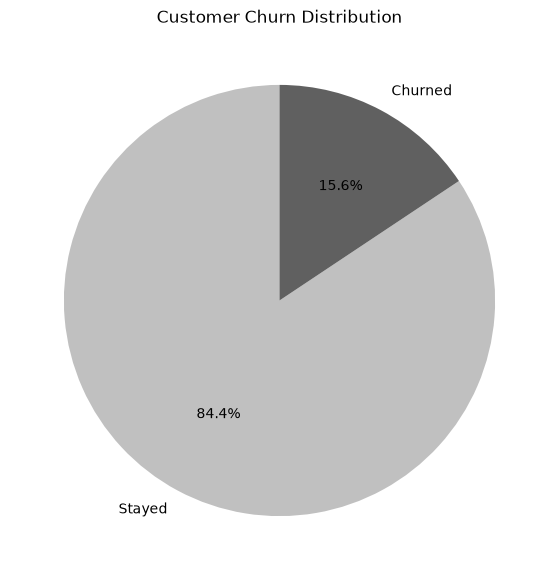

In [33]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 7))

plt.pie(
    churn_percentage,
    labels=['Stayed', 'Churned'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#C0C0C0', '#606060'],
    textprops={'color': 'Black'}
)

plt.title('Customer Churn Distribution', color='Black')
plt.show()

## 9. Tariff Plan and Customer Complaints

In [34]:
df.groupby('Tariff Plan')['Complains'].sum()

Tariff Plan
1    211
2     19
Name: Complains, dtype: int64

In [35]:
df.groupby('Tariff Plan')['Complains'].mean() * 100

Tariff Plan
1    8.050362
2    8.296943
Name: Complains, dtype: float64

## 10. Correlation Analysis

In [36]:
df[['Seconds of Use', 'Frequency of SMS']].corr()

,Seconds of Use,Frequency of SMS
Seconds of Use,1.000000,0.093073
Frequency of SMS,0.093073,1.000000


### Customer Value Distribution

In [37]:
df['Customer Value'].describe()

count    2850.000000
mean      474.990367
std       514.442198
min         0.000000
25%       117.527500
50%       232.520000
75%       790.080000
max      2165.280000
Name: Customer Value, dtype: float64

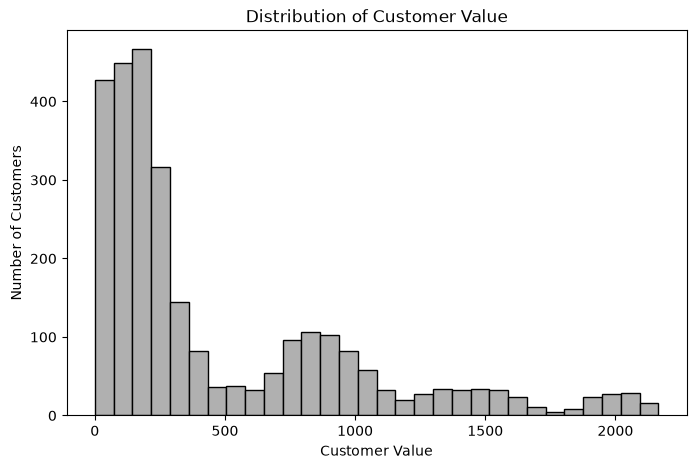

In [38]:
plt.figure(figsize=(8, 5))

plt.hist(df['Customer Value'], bins=30, color='#B0B0B0', edgecolor='black')

plt.title('Distribution of Customer Value')
plt.xlabel('Customer Value')
plt.ylabel('Number of Customers')

plt.show()

In [39]:
df[['Seconds of Use', 'Customer Value']].corr()

,Seconds of Use,Customer Value
Seconds of Use,1.000000,0.408536
Customer Value,0.408536,1.000000


In [40]:
df[['Frequency of SMS', 'Customer Value']].corr()

,Frequency of SMS,Customer Value
Frequency of SMS,1.000000,0.922852
Customer Value,0.922852,1.000000


In [41]:
df[['Frequency of use', 'Customer Value']].corr()

,Frequency of use,Customer Value
Frequency of use,1.000000,0.394647
Customer Value,0.394647,1.000000


### Scatter Plot: Call Usage vs Customer Value

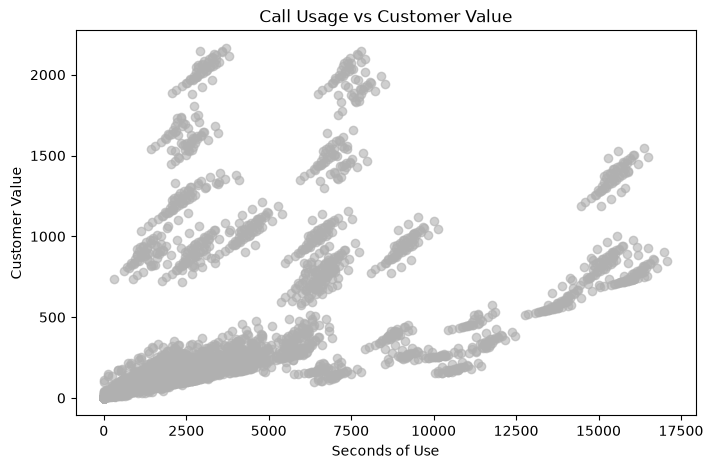

In [42]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Seconds of Use'], df['Customer Value'],color='#B0B0B0', alpha=0.6)

plt.title('Call Usage vs Customer Value')
plt.xlabel('Seconds of Use')
plt.ylabel('Customer Value')

plt.show()

### Scatter Plot: SMS Usage vs Customer Value

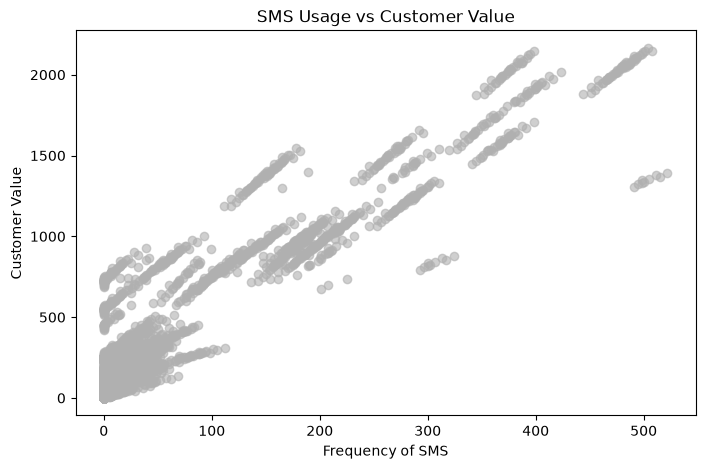

In [43]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Frequency of SMS'], df['Customer Value'],color='#B0B0B0', alpha=0.6)

plt.title('SMS Usage vs Customer Value')
plt.xlabel('Frequency of SMS')
plt.ylabel('Customer Value')

plt.show()

### Scatter Plot: Frequency of Use vs Customer Value

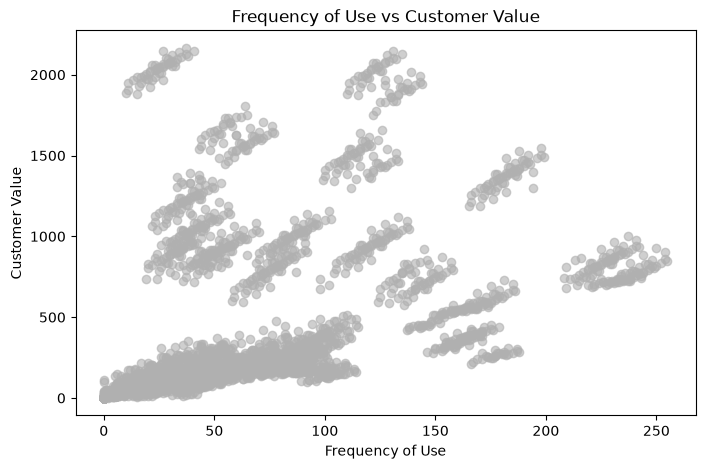

In [44]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Frequency of use'], df['Customer Value'],color='#B0B0B0', alpha=0.6)

plt.title('Frequency of Use vs Customer Value')
plt.xlabel('Frequency of Use')
plt.ylabel('Customer Value')

plt.show()

### Correlation Heatmap

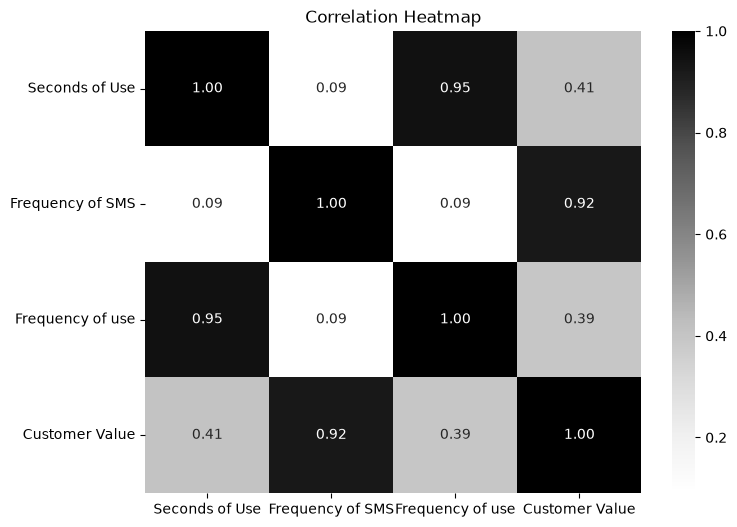

In [45]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[['Seconds of Use', 'Frequency of SMS',
        'Frequency of use', 'Customer Value']].corr(),
    annot=True,
    cmap='Greys',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

### Bar Chart: Customer Churn Rate by Complaints

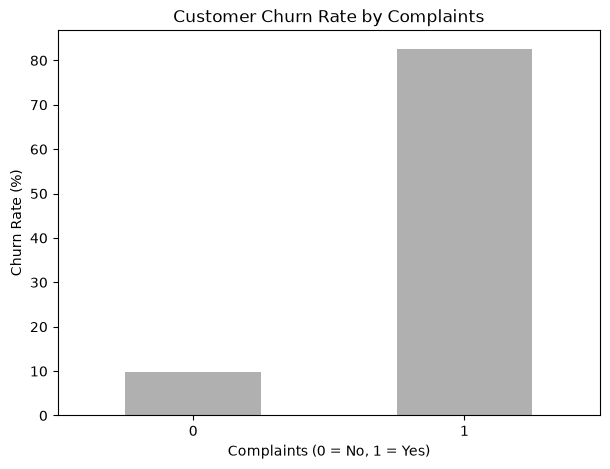

In [46]:
complaint_churn = df.groupby('Complains')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))

complaint_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Churn Rate by Complaints')
plt.xlabel('Complaints (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Customer Churn Rate by Age Group

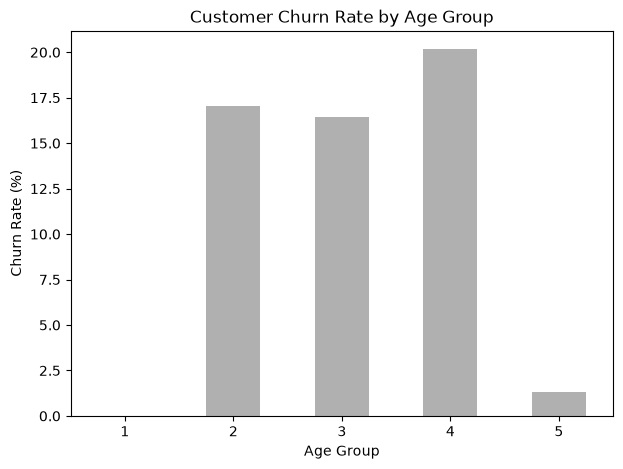

In [47]:
age_churn = df.groupby('Age Group')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))

age_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Customer Churn Rate by Tariff Plan

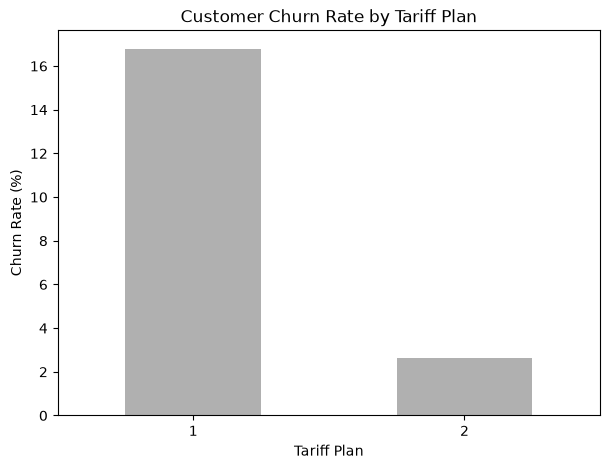

In [48]:
tariff_churn = df.groupby('Tariff Plan')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))

tariff_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Churn Rate by Tariff Plan')
plt.xlabel('Tariff Plan')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Customer Churn Rate by Status

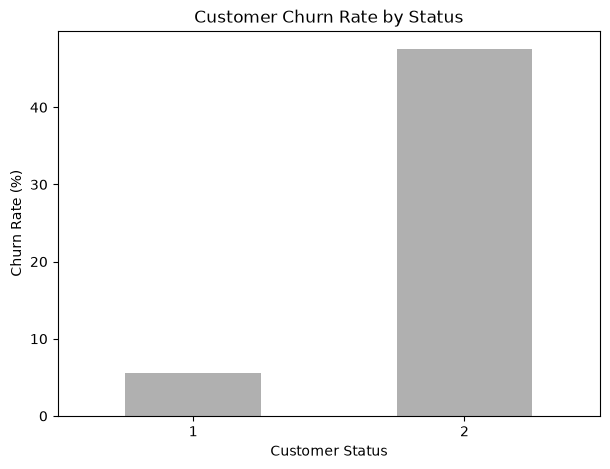

In [49]:
status_churn = df.groupby('Status')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))

status_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Churn Rate by Status')
plt.xlabel('Customer Status')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Average Customer Value by Churn Status

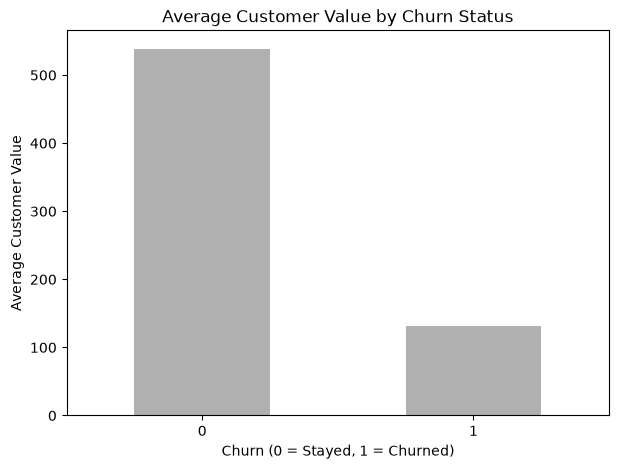

In [50]:
customer_value_churn = df.groupby('Churn')['Customer Value'].mean()

plt.figure(figsize=(7, 5))

customer_value_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Average Customer Value by Churn Status')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Average Customer Value')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Average Call Usage by Churn Status

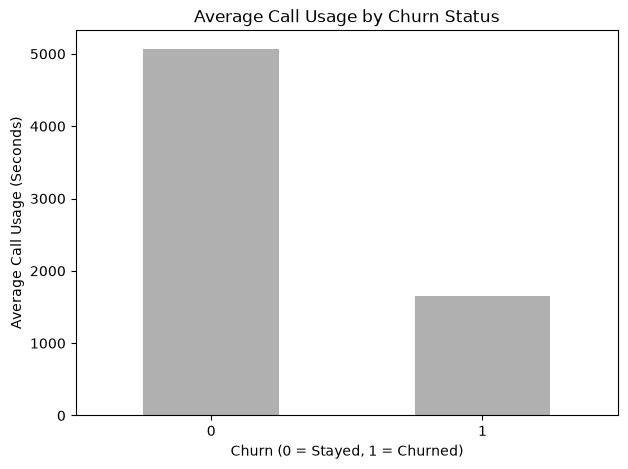

In [51]:
call_usage_churn = df.groupby('Churn')['Seconds of Use'].mean()

plt.figure(figsize=(7, 5))

call_usage_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Average Call Usage by Churn Status')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Average Call Usage (Seconds)')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Average SMS Usage by Churn Status

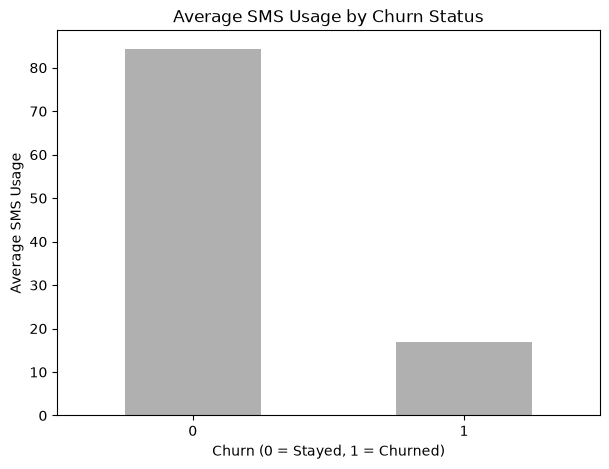

In [52]:
sms_usage_churn = df.groupby('Churn')['Frequency of SMS'].mean()

plt.figure(figsize=(7, 5))

sms_usage_churn.plot(kind='bar', color='#B0B0B0')

plt.title('Average SMS Usage by Churn Status')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Average SMS Usage')

plt.xticks(rotation=0)
plt.show()

### Bar Chart: Customer Complaint Rate by Tariff Plan

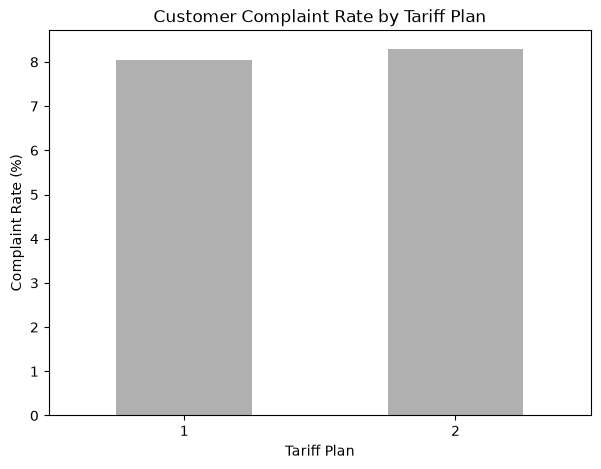

In [53]:
complaint_tariff = df.groupby('Tariff Plan')['Complains'].mean() * 100

plt.figure(figsize=(7, 5))

complaint_tariff.plot(kind='bar', color='#B0B0B0')

plt.title('Customer Complaint Rate by Tariff Plan')
plt.xlabel('Tariff Plan')
plt.ylabel('Complaint Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Scatter Plot: Call Usage vs Frequency of Use

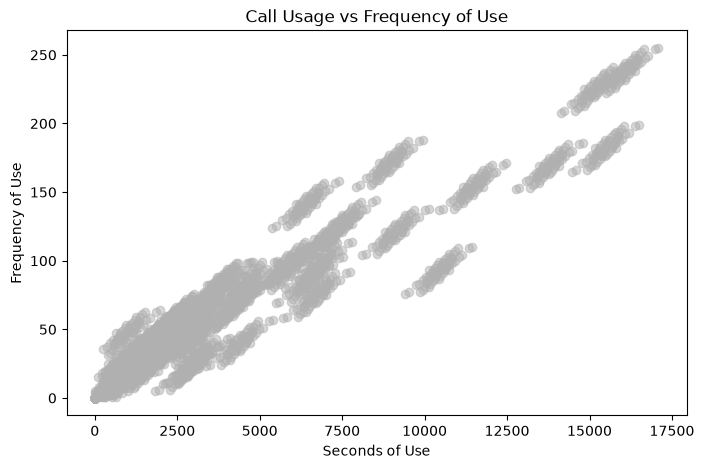

In [54]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Seconds of Use'], df['Frequency of use'], alpha=0.5, color='#B0B0B0')

plt.title('Call Usage vs Frequency of Use')
plt.xlabel('Seconds of Use')
plt.ylabel('Frequency of Use')

plt.show()

## 11. Key Findings

### 1. Overall Customer Churn
- Out of 2,850 customers, 446 customers (15.65%) churned.
- 2,404 customers (84.35%) remained with the telecom company.

### 2. Customer Complaints
- Customers who complained had a significantly higher churn rate (82.61%).
- Customers without complaints had a churn rate of 9.77%.

### 3. Customer Usage Behaviour
- Churned customers had considerably lower average call usage than retained customers.
- Churned customers also had considerably lower average SMS usage.

### 4. Customer Value
- Retained customers had an average customer value of 538.59.
- Churned customers had an average customer value of 132.18.

### 5. Age Group Analysis
- Age 45 recorded the highest churn rate (20.16%).
- Age 30 had the highest number of churned customers.

### 6. Tariff Plan Analysis
- Tariff Plan 1 recorded a churn rate of 16.79%.
- Tariff Plan 2 recorded a churn rate of 2.62%.

### 7. Correlation Analysis
- Frequency of SMS showed a very strong positive correlation with Customer Value (0.92).
- Seconds of Use showed a moderate positive correlation with Customer Value (0.41).
 ### 8. Subscription Length Analysis
- Retained customers had a slightly higher average subscription length (32.60) compared to churned customers (31.68).

## 12. Business Recommendations

Based on the analysis, the following actions are recommended:

1. **Improve Complaint Handling:** Investigate customer complaints quickly and provide effective solutions to reduce churn.

2. **Monitor Customer Usage:** Identify customers with declining call and SMS usage and offer suitable retention support.

3. **Focus on High-Risk Customers:** Pay attention to customer groups with higher observed churn rates.

4. **Review Tariff Plans:** Evaluate the differences in churn rates across tariff plans and understand customer preferences.

5. **Improve Customer Engagement:** Develop loyalty programmes and personalised offers to encourage customers to remain with the company.

6. **Retain High-Value Customers:** Identify valuable customers and provide services that improve their satisfaction and loyalty.

## 13. Conclusion

This project analysed telecom customer churn using Python and explored customer behaviour, service usage, complaints, and customer value.

The analysis revealed that customer complaints, lower service usage, and differences in tariff plans were associated with customer churn.

Data visualisations and correlation analysis helped identify important patterns in customer behaviour.

These findings can help telecom companies understand customer churn and develop better customer retention strategies.

Overall, this project demonstrates how data analysis can support business decision-making and improve customer retention.